## Time-of-Day Vessel Movement Dynamics (Flag 14)

### Dataset Overview
A constructed Danish AIS-style North Sea case containing 88 complete trajectories grouped by departure period across early morning, midday, late afternoon, and evening/night, with static vessel dimensions and type.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze how vessel traffic and movement patterns vary across different periods of the day.

Role: Maritime traffic analyst


Category: time-of-day vessel movement dynamics

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do the length-and-width vessel-size composition and short-term COG changes vary across time periods?

#### Analysis action

Classify a vessel as small only when both length is below 70 m and width is below 15 m, assign trajectories by departure period, then compare the hourly rate of COG changes exceeding 5 degrees between adjacent reports no more than 7 minutes apart.

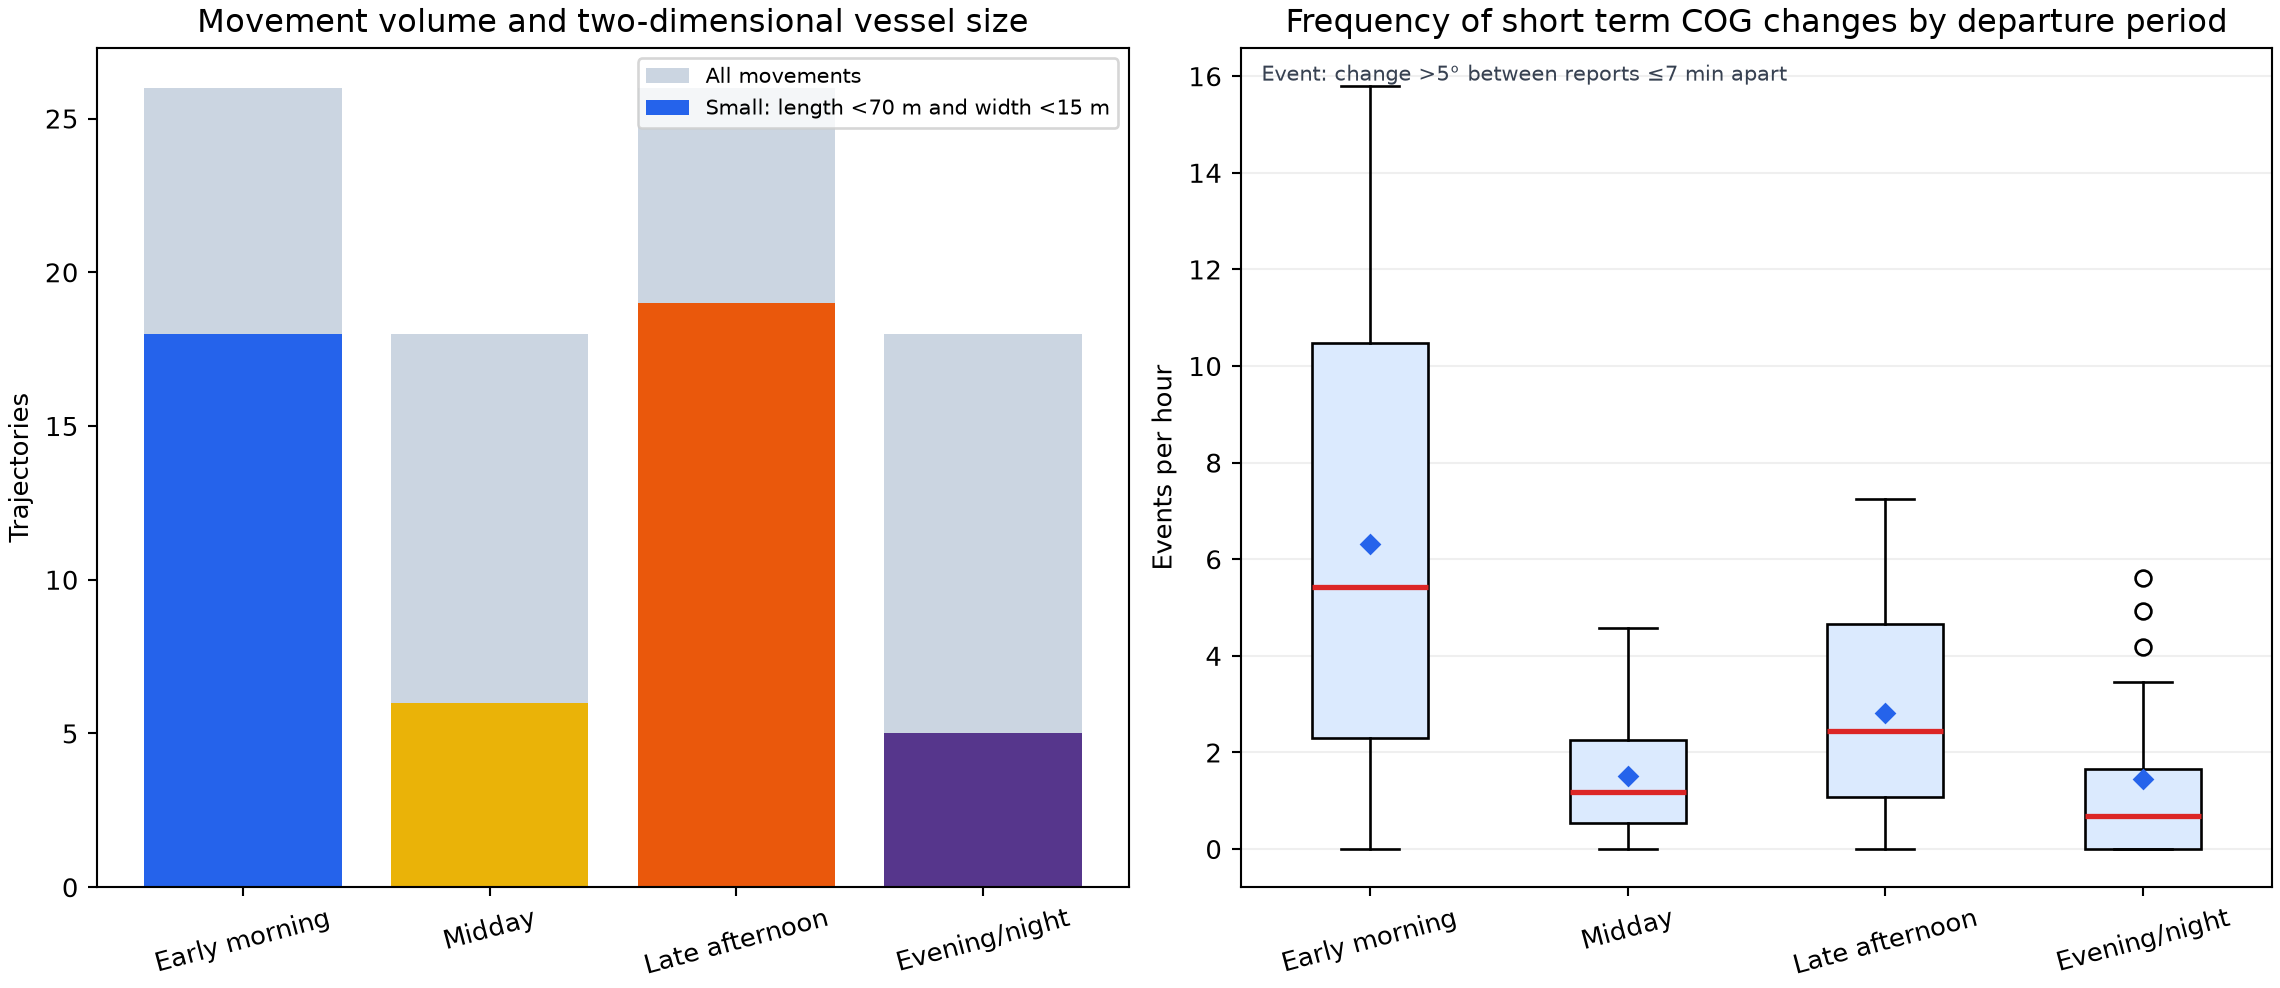

In [ ]:
import pandas as pd
import numpy as np
points=pd.read_csv(dataset_path).sort_values(['trajectory_id','point_index']); vessels=pd.read_csv(user_dataset_path); points['timestamp']=pd.to_datetime(points.timestamp)
delta=points.groupby('trajectory_id').cog.diff(); interval=points.groupby('trajectory_id').timestamp.diff().dt.total_seconds()/60; points['short_cog_change']=(abs((delta+180)%360-180)>5)&(interval<=7)
trips=points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'),start=('timestamp','min'),end=('timestamp','max'),short_cog_changes=('short_cog_change','sum')).reset_index().merge(vessels,on='vessel_id'); trips['duration_hours']=(trips.end-trips.start).dt.total_seconds()/3600; trips['short_cog_change_rate_per_hour']=trips.short_cog_changes/trips.duration_hours
hour=trips.start.dt.hour; trips['period']=np.select([(hour>=4)&(hour<9),(hour>=9)&(hour<14),(hour>=14)&(hour<19)],['early_morning','midday','late_afternoon'],default='evening_night'); trips['small_vessel']=(trips.length_m<70)&(trips.width_m<15)
summary=trips.groupby('period').agg(trajectories=('trajectory_id','size'),small_vessels=('small_vessel','sum'),mean_event_rate_per_hour=('short_cog_change_rate_per_hour','mean'),median_event_rate_per_hour=('short_cog_change_rate_per_hour','median')); print(summary.round(2).to_string())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/small_vessels_and_cog_changes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "time_period_vessel_size_and_turning",
  "insight": "In the early morning and later afternoon, traffic contains more small-vessel movements and more frequent short-term COG changes than during comparable evening and midday periods.",
  "insight_value": {
    "trajectory_counts": {
      "early_morning": 26,
      "midday": 18,
      "late_afternoon": 26,
      "evening_night": 18
    },
    "small_vessel_definition": {
      "length_m_below": 70.0,
      "width_m_below": 15.0
    },
    "small_vessel_counts": {
      "early_morning": 18,
      "midday": 6,
      "late_afternoon": 19,
      "evening_night": 5
    },
    "short_cog_change_definition": {
      "change_exceeds_deg": 5.0,
      "adjacent_report_interval_at_most_minutes": 7.0
    },
    "mean_short_cog_change_rate_per_hour": {
      "early_morning": 6.32,
      "midday": 1.52,
      "late_afternoon": 2.83,
      "evening_night": 1.45
    },
    "median_short_cog_change_rate_per_hour": {
      "early_morning": 5.43,
      "midday": 1.18,
      "late_afternoon": 2.44,
      "evening_night": 0.68
    }
  },
  "plot": {
    "plot_type": "paired_temporal_comparison",
    "title": "Small-vessel Activity and COG Changes",
    "file": "visualizations/small_vessels_and_cog_changes.png",
    "description": "Temporal distributions expose the stated time-of-day movement difference."
  },
  "question": "How do the length-and-width vessel-size composition and short-term COG changes vary across time periods?",
  "actionable_insight": "Classify a vessel as small only when both length is below 70 m and width is below 15 m, assign trajectories by departure period, then compare the hourly rate of COG changes exceeding 5 degrees between adjacent reports no more than 7 minutes apart.",
  "code": "import pandas as pd\nimport numpy as np\npoints=pd.read_csv(dataset_path).sort_values(['trajectory_id','point_index']); vessels=pd.read_csv(user_dataset_path); points['timestamp']=pd.to_datetime(points.timestamp)\ndelta=points.groupby('trajectory_id').cog.diff(); interval=points.groupby('trajectory_id').timestamp.diff().dt.total_seconds()/60; points['short_cog_change']=(abs((delta+180)%360-180)>5)&(interval<=7)\ntrips=points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'),start=('timestamp','min'),end=('timestamp','max'),short_cog_changes=('short_cog_change','sum')).reset_index().merge(vessels,on='vessel_id'); trips['duration_hours']=(trips.end-trips.start).dt.total_seconds()/3600; trips['short_cog_change_rate_per_hour']=trips.short_cog_changes/trips.duration_hours\nhour=trips.start.dt.hour; trips['period']=np.select([(hour>=4)&(hour<9),(hour>=9)&(hour<14),(hour>=14)&(hour<19)],['early_morning','midday','late_afternoon'],default='evening_night'); trips['small_vessel']=(trips.length_m<70)&(trips.width_m<15)\nsummary=trips.groupby('period').agg(trajectories=('trajectory_id','size'),small_vessels=('small_vessel','sum'),mean_event_rate_per_hour=('short_cog_change_rate_per_hour','mean'),median_event_rate_per_hour=('short_cog_change_rate_per_hour','median')); print(summary.round(2).to_string())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "vessel_length",
    "vessel_width",
    "course_over_ground",
    "vessel_id"
  ]
}

### **Question 2**: How do vessel speed level and stability vary across the four time periods, and is late-afternoon variability especially strong for fishing vessels?

#### Analysis action

Compare trajectory mean SOG and within-trajectory SOG variability by departure period, separating fishing from other vessels when assessing variability.

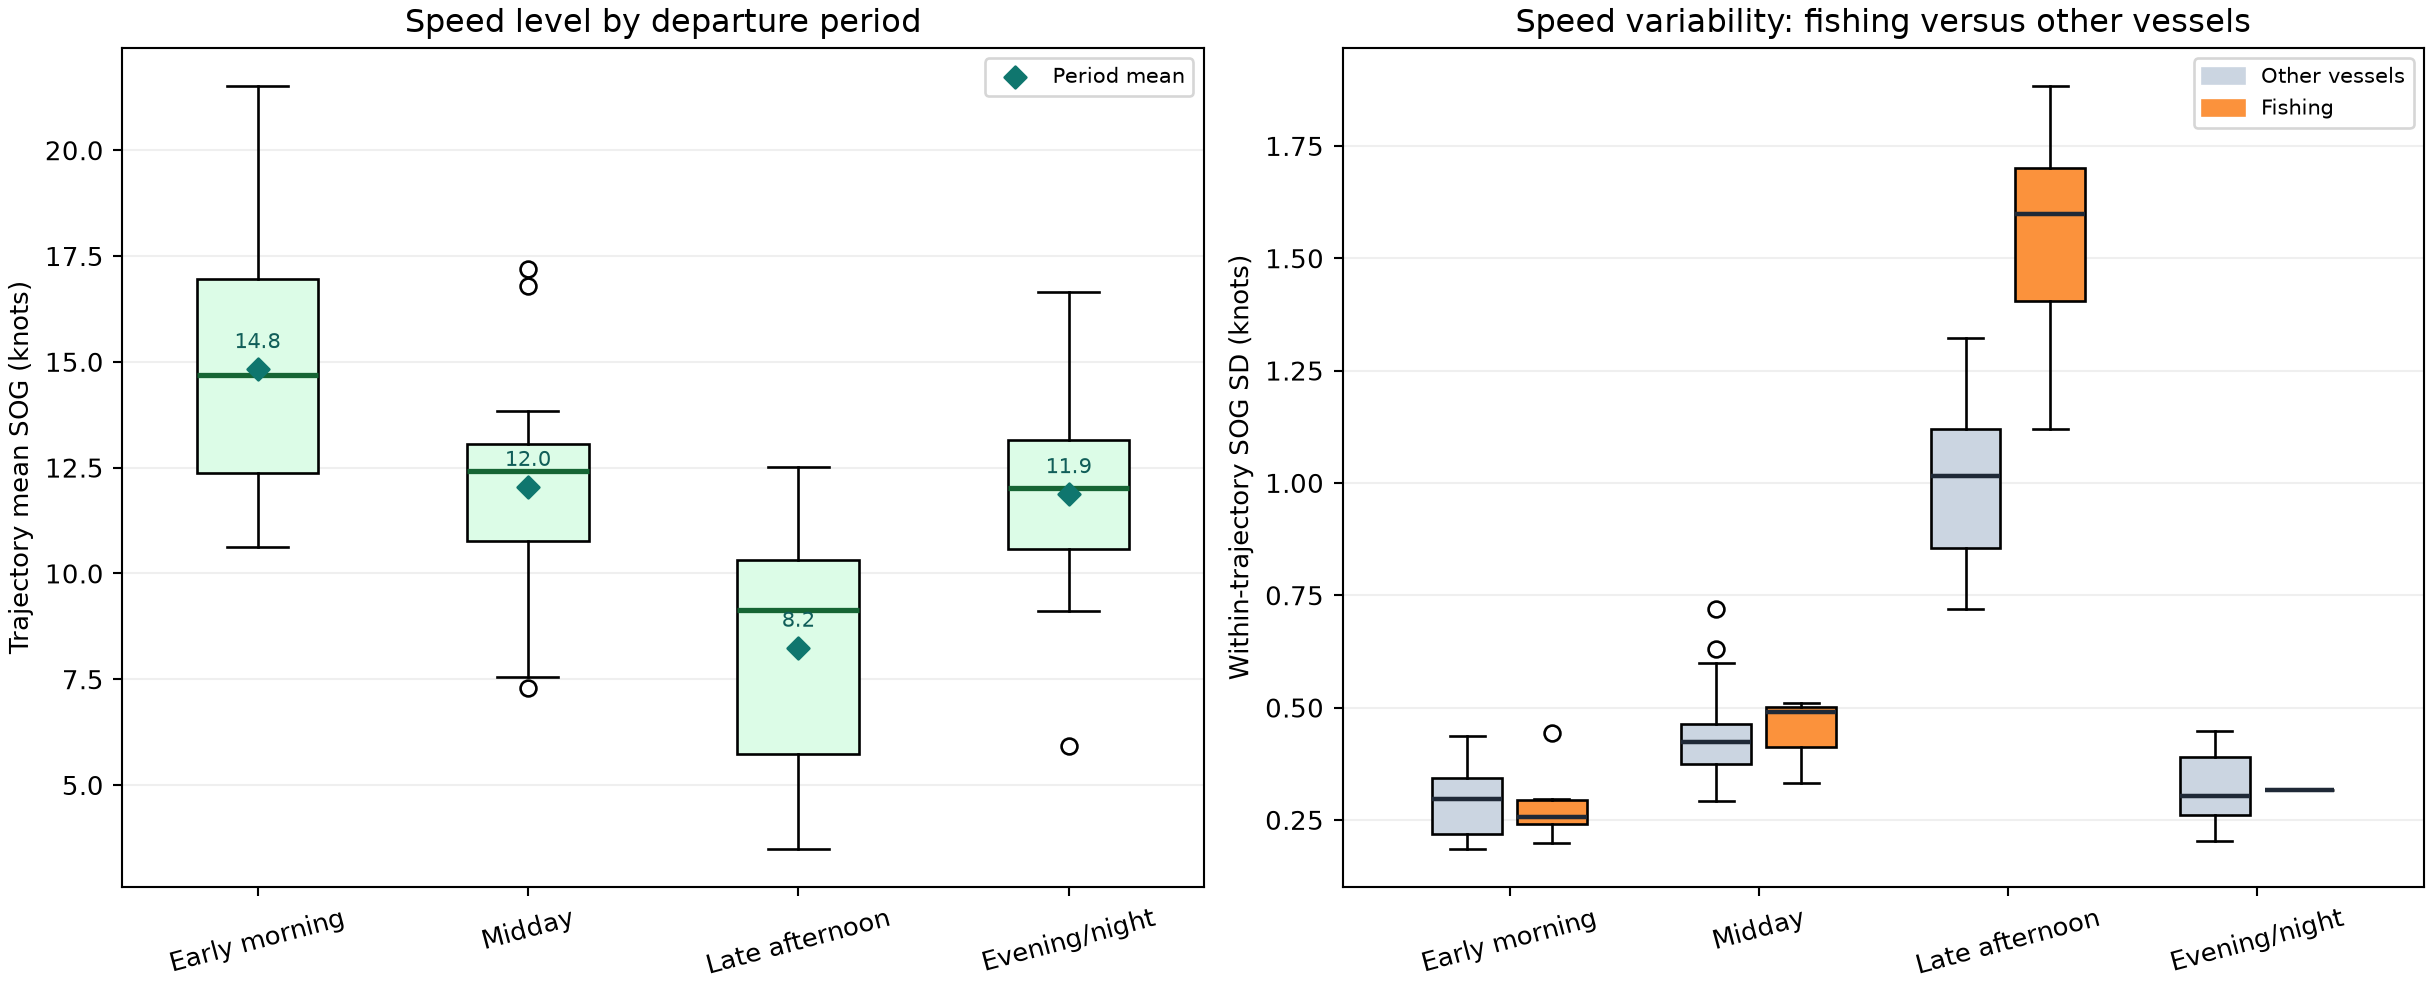

In [ ]:
import pandas as pd
import numpy as np
points=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); points['timestamp']=pd.to_datetime(points.timestamp)
trips=points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'),start=('timestamp','min'),mean_sog=('sog_knots','mean'),sog_sd=('sog_knots','std')).reset_index().merge(vessels,on='vessel_id')
hour=trips.start.dt.hour; trips['period']=np.select([(hour>=4)&(hour<9),(hour>=9)&(hour<14),(hour>=14)&(hour<19)],['early_morning','midday','late_afternoon'],default='evening_night'); trips['vessel_group']=np.where(trips.ship_type.eq('Fishing'),'fishing','other_vessels')
print(trips.groupby('period').agg(mean_trajectory_sog=('mean_sog','mean'),median_sog_sd=('sog_sd','median'))); print(trips.pivot_table(index='period',columns='vessel_group',values='sog_sd',aggfunc='median'))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_stability_by_time.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "time_period_speed_dynamics",
  "insight": "Generally, speeds are stable and higher in the mornings but lower and more variable in the afternoons, especially for fishing vessels.",
  "insight_value": {
    "mean_trajectory_speed_knots": {
      "early_morning": 14.83,
      "midday": 12.04,
      "late_afternoon": 8.24,
      "evening_night": 11.87
    },
    "median_speed_sd_knots": {
      "early_morning": 0.26,
      "midday": 0.42,
      "late_afternoon": 1.14,
      "evening_night": 0.31
    },
    "median_speed_sd_knots_by_vessel_group": {
      "fishing": {
        "early_morning": 0.26,
        "midday": 0.49,
        "late_afternoon": 1.6,
        "evening_night": 0.32
      },
      "other_vessels": {
        "early_morning": 0.3,
        "midday": 0.42,
        "late_afternoon": 1.01,
        "evening_night": 0.3
      }
    }
  },
  "plot": {
    "plot_type": "paired_temporal_comparison",
    "title": "Speed Stability across Time",
    "file": "visualizations/speed_stability_by_time.png",
    "description": "Temporal distributions expose the stated time-of-day movement difference."
  },
  "question": "How do vessel speed level and stability vary across the four time periods, and is late-afternoon variability especially strong for fishing vessels?",
  "actionable_insight": "Compare trajectory mean SOG and within-trajectory SOG variability by departure period, separating fishing from other vessels when assessing variability.",
  "code": "import pandas as pd\nimport numpy as np\npoints=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); points['timestamp']=pd.to_datetime(points.timestamp)\ntrips=points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'),start=('timestamp','min'),mean_sog=('sog_knots','mean'),sog_sd=('sog_knots','std')).reset_index().merge(vessels,on='vessel_id')\nhour=trips.start.dt.hour; trips['period']=np.select([(hour>=4)&(hour<9),(hour>=9)&(hour<14),(hour>=14)&(hour<19)],['early_morning','midday','late_afternoon'],default='evening_night'); trips['vessel_group']=np.where(trips.ship_type.eq('Fishing'),'fishing','other_vessels')\nprint(trips.groupby('period').agg(mean_trajectory_sog=('mean_sog','mean'),median_sog_sd=('sog_sd','median'))); print(trips.pivot_table(index='period',columns='vessel_group',values='sog_sd',aggfunc='median'))",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "ship_type",
    "point_speed",
    "vessel_id"
  ]
}

### **Question 3**: How does heading–COG consistency change in the evening and at night, and how is the gap associated with vessel length and width?

#### Analysis action

Use the circular absolute heading–COG gap, where a smaller value means greater consistency, and relate evening/night-departure gaps to the combined length-by-width footprint.

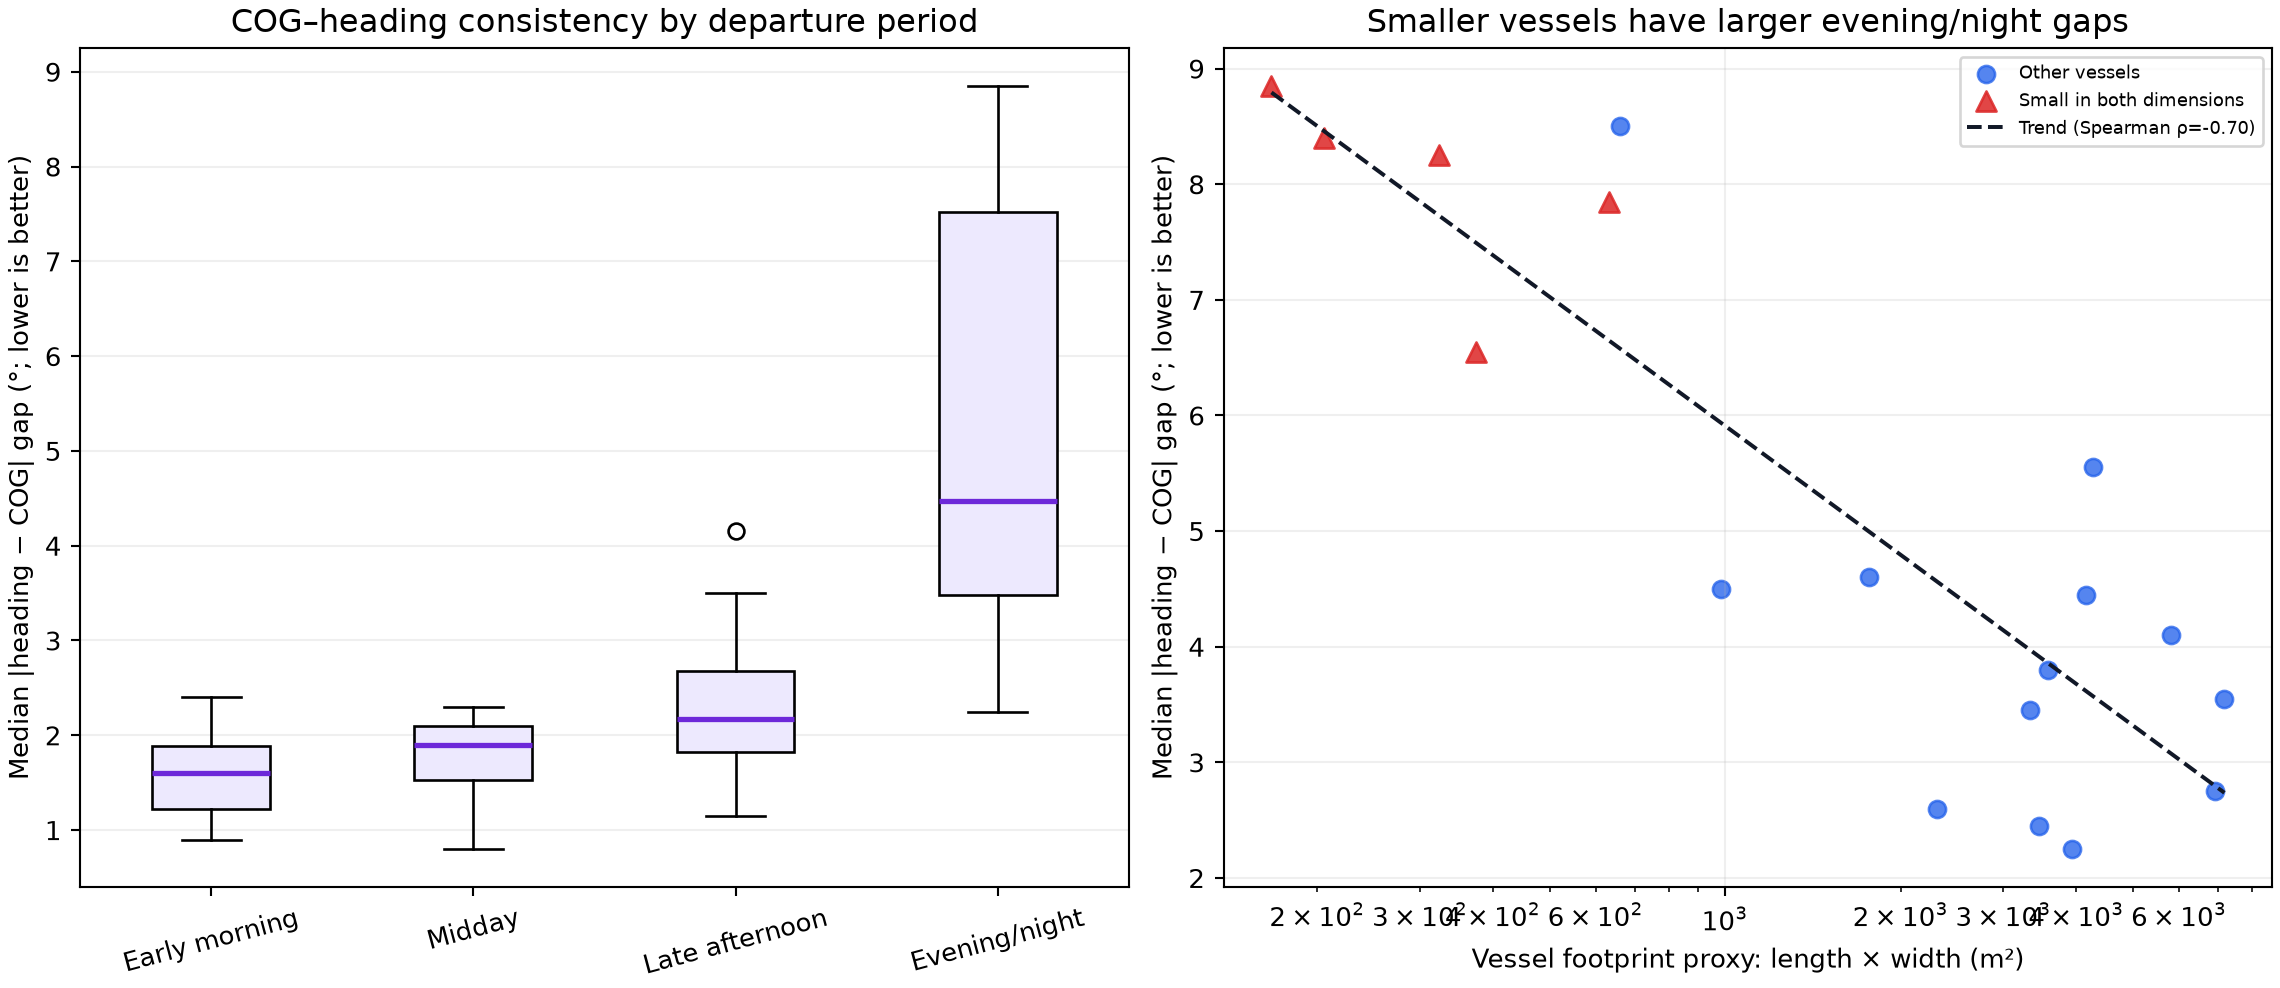

In [ ]:
import pandas as pd
points=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); points['timestamp']=pd.to_datetime(points.timestamp); points['gap']=abs((points.heading-points.cog+180)%360-180)
trips=points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'),start=('timestamp','min'),median_gap=('gap','median')).reset_index().merge(vessels,on='vessel_id'); hour=trips.start.dt.hour; night=trips[(hour>=19)|(hour<4)].copy(); night['footprint_m2']=night.length_m*night.width_m; night['small_vessel']=(night.length_m<70)&(night.width_m<15)
print(night.groupby('small_vessel').median_gap.agg(['count','median'])); print(night[['footprint_m2','median_gap']].corr(method='spearman'))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/heading_cog_consistency.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "time_period_heading_cog_consistency",
  "insight": "In the evenings and at night, the consistency between COG and heading decreases, especially for smaller vessels.",
  "insight_value": {
    "median_heading_cog_gap_deg": {
      "early_morning": 1.6,
      "midday": 1.9,
      "late_afternoon": 2.17,
      "evening_night": 4.48
    },
    "evening_night_median_heading_cog_gap_deg_by_size": {
      "small_vessels": 8.25,
      "other_vessels": 3.8
    },
    "evening_night_footprint_gap_spearman_rho": -0.705,
    "small_vessel_definition": {
      "length_m_below": 70.0,
      "width_m_below": 15.0
    }
  },
  "plot": {
    "plot_type": "paired_temporal_comparison",
    "title": "Evening and Night COG–Heading Consistency",
    "file": "visualizations/heading_cog_consistency.png",
    "description": "Temporal distributions expose the stated time-of-day movement difference."
  },
  "question": "How does heading–COG consistency change in the evening and at night, and how is the gap associated with vessel length and width?",
  "actionable_insight": "Use the circular absolute heading–COG gap, where a smaller value means greater consistency, and relate evening/night-departure gaps to the combined length-by-width footprint.",
  "code": "import pandas as pd\npoints=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); points['timestamp']=pd.to_datetime(points.timestamp); points['gap']=abs((points.heading-points.cog+180)%360-180)\ntrips=points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'),start=('timestamp','min'),median_gap=('gap','median')).reset_index().merge(vessels,on='vessel_id'); hour=trips.start.dt.hour; night=trips[(hour>=19)|(hour<4)].copy(); night['footprint_m2']=night.length_m*night.width_m; night['small_vessel']=(night.length_m<70)&(night.width_m<15)\nprint(night.groupby('small_vessel').median_gap.agg(['count','median'])); print(night[['footprint_m2','median_gap']].corr(method='spearman'))",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "vessel_length",
    "vessel_width",
    "heading",
    "course_over_ground",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 14)

In the early morning and later afternoon, traffic contains more small-vessel movements and more frequent short-term COG changes than during comparable evening and midday periods. Generally, speeds are stable and higher in the mornings but lower and more variable in the afternoons, especially for fishing vessels. In the evenings and at night, the consistency between COG and heading decreases, especially for smaller vessels.